## NGC 188 and NGC 7789


Load the data

Read the two original CSVs and check how many stars have colors and radial velocities. Keep Gaia IDs as text so their digits stay exact.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter
from IPython.display import display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'outputs').is_dir())
data = {n: pd.read_csv(ROOT/f'outputs/NGC{n}-result_output/NGC{n}-result_cluster_membership_results.csv', dtype={'source_id':str}) for n in (188,7789)}
pd.set_option('display.max_columns', 12)
display(pd.DataFrame([{'cluster':n,'stars':len(d),'missing color or G':d[['bp_rp','phot_g_mean_mag']].isna().any(axis=1).sum(),'radial velocities':d.radial_velocity.notna().sum()} for n,d in data.items()]))

,cluster,stars,missing color or G,radial velocities
0,188,6327,74,313
1,7789,73625,2110,2366


Use the saved membership results

Count the membership tiers already assigned by the pipeline. For the later object tables, use saved final probability of at least 50%, and show which candidates also reach 80%. No new cluster finding or astrometric selection is performed.

In [2]:
models={'PM':'pm_only_prob','Parallax':'plx_only_prob','Combined':'joint_prob','Final':'final_member_prob'}
samples={n:d.loc[d.final_member_prob>=.5].copy() for n,d in data.items()}
rows=[]
for n,d in data.items():
    for label,col in models.items():
        rows.append({'cluster':n,'model':label,'P >= 0.5':int((d[col]>=.5).sum()),'P >= 0.8':int((d[col]>=.8).sum()),'maximum probability':d[col].max()})
display(pd.DataFrame(rows).round(3))
for n,d in data.items():
    print(f'NGC {n}: membership tiers from the CSV')
    display(pd.DataFrame({label:d[col].value_counts() for label,col in [('PM','pm_only_tier'),('Parallax','plx_only_tier'),('Combined','joint_tier'),('Final','final_tier')]}).fillna(0).astype(int))

,cluster,model,P >= 0.5,P >= 0.8,maximum probability
0,188,PM,3075,2193,0.919
1,188,Parallax,4054,0,0.649
2,188,Combined,2131,1648,0.994
3,188,Final,2122,1639,0.994
4,7789,PM,26489,0,0.746
5,7789,Parallax,0,0,0.319
6,7789,Combined,22017,253,0.820
7,7789,Final,22017,253,0.820


NGC 188: membership tiers from the CSV


,PM,Parallax,Combined,Final
core,2193,0,1648,1639
non-member,2922,938,3924,3924
possible,518,2876,432,441
probable,694,2513,323,323


NGC 7789: membership tiers from the CSV


,PM,Parallax,Combined,Final
core,0,0,253,253
non-member,34880,59994,38525,38525
possible,22614,13631,21784,21784
probable,16131,0,13063,13063


Compare the models on the color and brightness diagram

For each model, plot stars with saved probability at least 50%. Orange points also reach 80%. Using the same thresholds shows how the models select different stellar sequences. An empty panel means that model has no stars above 50%.

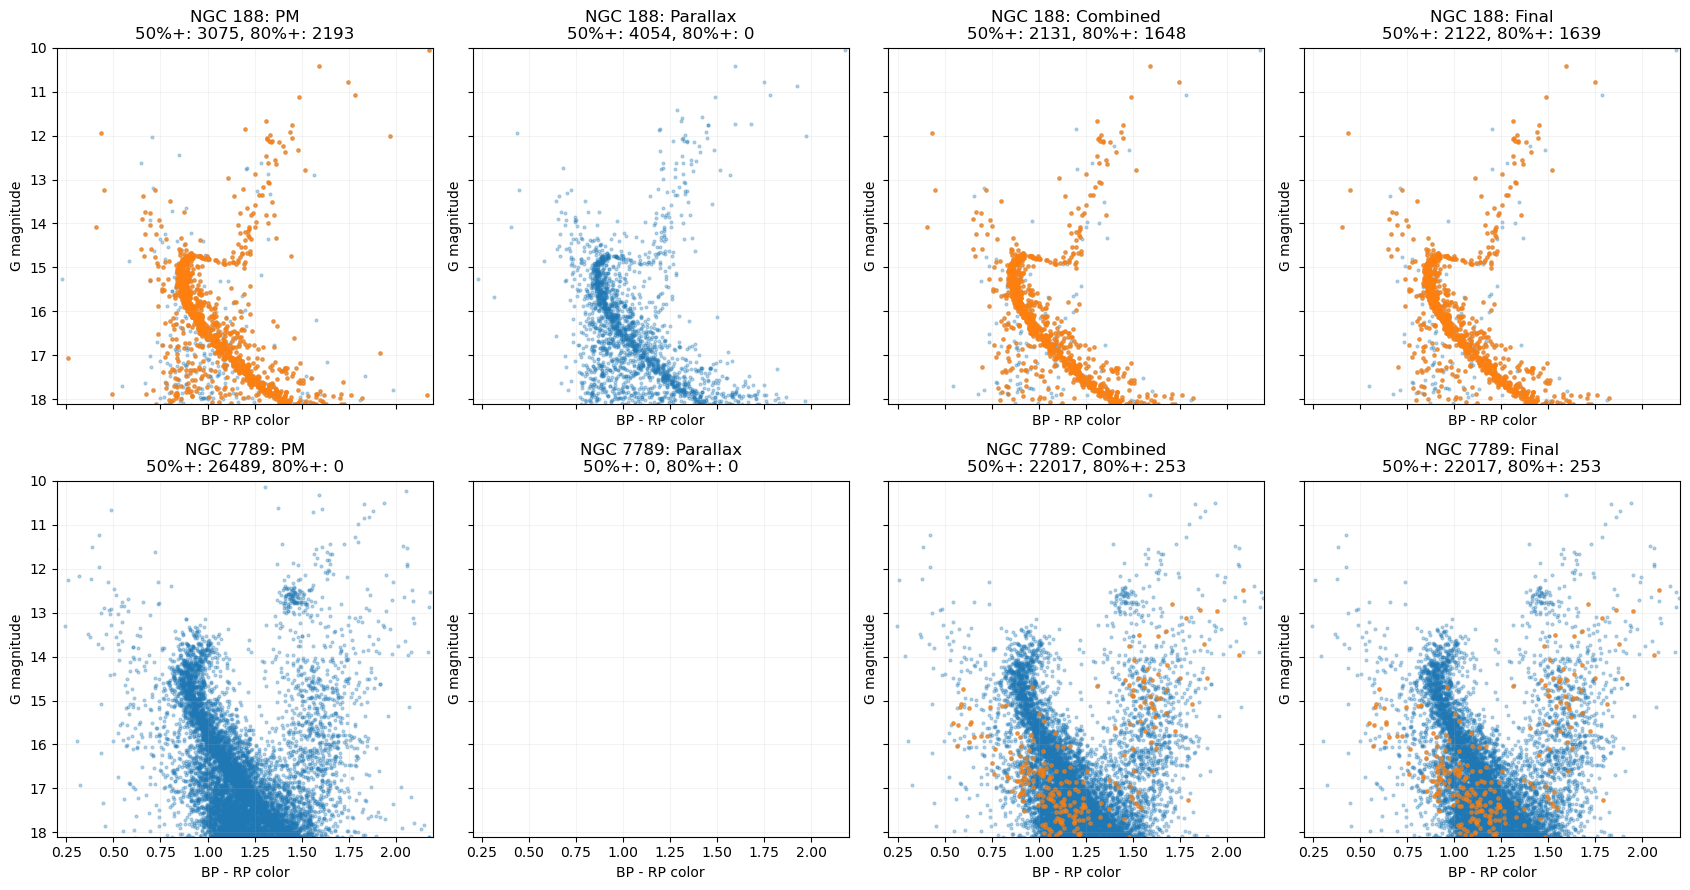

In [3]:
fig,axes=plt.subplots(2,4,figsize=(17,9),sharex=True,sharey=True)
for row,(n,d) in enumerate(data.items()):
    for ax,(label,col) in zip(axes[row],models.items()):
        selected=d.loc[d[col]>=.5]
        core=d.loc[d[col]>=.8]
        ax.scatter(selected.bp_rp,selected.phot_g_mean_mag,s=4,color='tab:blue',alpha=.3,rasterized=True)
        ax.scatter(core.bp_rp,core.phot_g_mean_mag,s=6,color='tab:orange',alpha=.6,rasterized=True)
        ax.set(title=f'NGC {n}: {label}\n50%+: {len(selected)}, 80%+: {len(core)}',xlabel='BP - RP color',ylabel='G magnitude',xlim=(.2,2.2),ylim=(18.1,10))
        ax.grid(alpha=.15)
plt.tight_layout(); plt.show()

Where the models agree and disagree

Compare the saved probabilities directly and count overlap at 50%. This shows whether the combined result follows the PM and parallax models. These are model comparisons, not a new membership calculation.

NGC 188: stars above 50% in both models (diagonal = model total)


,PM,Parallax,Combined,Final
PM,3075,2363,2085,2082
Parallax,2363,4054,1795,1791
Combined,2085,1795,2131,2122
Final,2082,1791,2122,2122


NGC 7789: stars above 50% in both models (diagonal = model total)


,PM,Parallax,Combined,Final
PM,26489,0,20444,20444
Parallax,0,0,0,0
Combined,20444,0,22017,22017
Final,20444,0,22017,22017


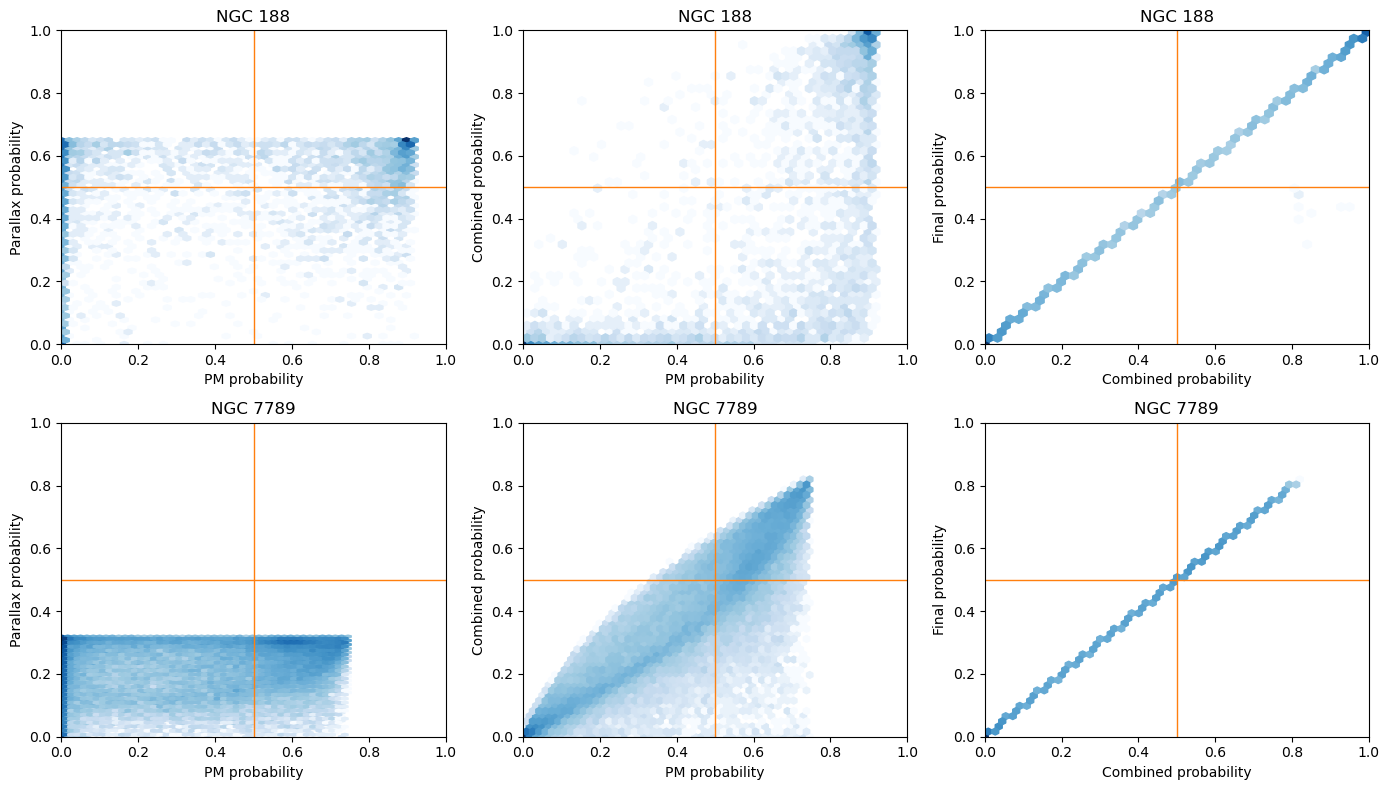

In [4]:
fig,axes=plt.subplots(2,3,figsize=(14,8))
pairs=[('PM','Parallax'),('PM','Combined'),('Combined','Final')]
for row,(n,d) in enumerate(data.items()):
    for ax,(left,right) in zip(axes[row],pairs):
        ax.hexbin(d[models[left]],d[models[right]],gridsize=45,mincnt=1,bins='log',cmap='Blues')
        ax.axvline(.5,color='tab:orange',linewidth=1); ax.axhline(.5,color='tab:orange',linewidth=1)
        ax.set(title=f'NGC {n}',xlabel=f'{left} probability',ylabel=f'{right} probability',xlim=(0,1),ylim=(0,1))
    masks={label:d[col]>=.5 for label,col in models.items()}
    overlap=pd.DataFrame({right:{left:int((masks[left]&masks[right]).sum()) for left in models} for right in models})
    print(f'NGC {n}: stars above 50% in both models (diagonal = model total)')
    display(overlap)
plt.tight_layout(); plt.show()

Inspect blue and red candidates in the saved final sample

Use the final 50%+ stars from the CSV and simple color and magnitude boxes to highlight blue-straggler-like and red-displaced objects. Show the 80%+ subset separately in the counts. Red boxes include possible sub-subgiants and red stragglers, but can also contain ordinary giants or binaries.

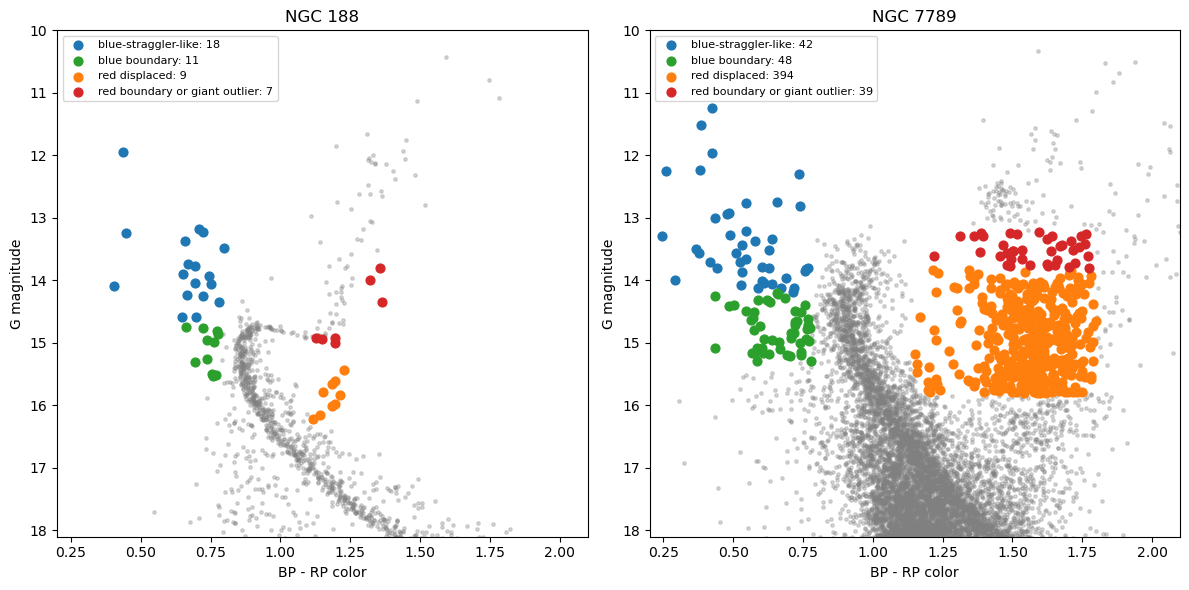

NGC 188: 45 objects in the inspection boxes


,stars,saved_core
region,,
blue boundary,11,7
blue-straggler-like,18,16
red boundary or giant outlier,7,3
red displaced,9,4


Showing up to 8 objects per region, highest saved probability first. All candidates remain in the candidates dictionary.


,source_id,region,phot_g_mean_mag,bp_rp,radial_velocity,phot_variable_flag,final_member_prob,saved core
0,573943149851092736,blue boundary,14.865,0.775,NaN,NOT_AVAILABLE,0.991,True
1,573939679517550848,blue boundary,15.261,0.736,NaN,NOT_AVAILABLE,0.991,True
2,573941809821331456,blue boundary,15.512,0.771,NaN,NOT_AVAILABLE,0.990,True
3,573944077564006528,blue boundary,14.741,0.662,NaN,NOT_AVAILABLE,0.988,True
4,573944283722429952,blue boundary,14.986,0.762,NaN,VARIABLE,0.987,True
5,573947444818423680,blue boundary,15.492,0.757,NaN,NOT_AVAILABLE,0.929,True
6,573965689839593472,blue boundary,15.531,0.759,NaN,NOT_AVAILABLE,0.840,True
7,573943871405571328,blue boundary,15.308,0.694,NaN,NOT_AVAILABLE,0.734,False
8,573941397504457344,blue-straggler-like,13.902,0.653,-44.797,NOT_AVAILABLE,0.993,True
9,573941294425258496,blue-straggler-like,14.344,0.781,-41.278,NOT_AVAILABLE,0.993,True


NGC 7789: 523 objects in the inspection boxes


,stars,saved_core
region,,
blue boundary,48,5
blue-straggler-like,42,0
red boundary or giant outlier,39,4
red displaced,394,33


Showing up to 8 objects per region, highest saved probability first. All candidates remain in the candidates dictionary.


,source_id,region,phot_g_mean_mag,bp_rp,radial_velocity,phot_variable_flag,final_member_prob,saved core
0,1995079658387248000,blue boundary,15.086,0.586,NaN,NOT_AVAILABLE,0.817,True
1,1995080826618300032,blue boundary,15.148,0.743,NaN,NOT_AVAILABLE,0.809,True
2,1998085894972110592,blue boundary,15.154,0.579,NaN,NOT_AVAILABLE,0.809,True
3,1995083815915526656,blue boundary,15.172,0.628,NaN,NOT_AVAILABLE,0.808,True
4,1995076394212435072,blue boundary,14.730,0.597,NaN,NOT_AVAILABLE,0.803,True
5,1995019735002059648,blue boundary,15.297,0.585,NaN,NOT_AVAILABLE,0.795,False
6,1998078988663802496,blue boundary,15.165,0.565,NaN,NOT_AVAILABLE,0.792,False
7,1995086599054724608,blue boundary,14.637,0.563,NaN,NOT_AVAILABLE,0.791,False
8,1998102937402247808,blue-straggler-like,14.072,0.529,NaN,NOT_AVAILABLE,0.793,False
9,1995066292449120896,blue-straggler-like,12.808,0.737,NaN,NOT_AVAILABLE,0.789,False


In [5]:
candidates={}
colors={'blue-straggler-like':'tab:blue','blue boundary':'tab:green','red displaced':'tab:orange','red boundary or giant outlier':'tab:red'}
fig,axes=plt.subplots(1,2,figsize=(12,6))
for ax,(n,d) in zip(axes,samples.items()):
    g,c=d.phot_g_mean_mag,d.bp_rp
    if n==188:
        boxes={'blue-straggler-like':(g<14.7)&c.between(.2,.83,inclusive='neither'),'blue boundary':g.between(14.7,15.6,inclusive='left')&c.between(.2,.78,inclusive='neither'),'red displaced':g.between(15.05,16.3,inclusive='neither')&c.between(1.1,1.8,inclusive='neither'),'red boundary or giant outlier':((g>14.9)&(g<=15.05)&c.between(1.1,1.8,inclusive='neither'))|(g.between(13.6,14.85,inclusive='neither')&c.between(1.32,2,inclusive='neither'))}
    else:
        boxes={'blue-straggler-like':(g<14.2)&c.between(.2,.78,inclusive='neither'),'blue boundary':g.between(14.2,15.3,inclusive='left')&c.between(.2,.78,inclusive='neither'),'red displaced':g.between(13.8,15.8,inclusive='neither')&c.between(1.15,1.8,inclusive='neither'),'red boundary or giant outlier':(g>13.2)&(g<=13.8)&c.between(1.18,1.8,inclusive='neither')}
    ax.scatter(c,g,s=6,color='gray',alpha=.3)
    parts=[]
    for label,mask in boxes.items():
        part=d.loc[mask].copy(); part['region']=label; parts.append(part)
        ax.scatter(part.bp_rp,part.phot_g_mean_mag,s=40,color=colors[label],label=f'{label}: {len(part)}')
    candidates[n]=pd.concat(parts).drop_duplicates('source_id')
    candidates[n]['saved core']=candidates[n].final_member_prob>=.8
    ax.set(title=f'NGC {n}',xlabel='BP - RP color',ylabel='G magnitude',xlim=(.2,2.1),ylim=(18.1,10)); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
columns=['source_id','region','phot_g_mean_mag','bp_rp','radial_velocity','phot_variable_flag','final_member_prob','saved core']
for n,d in candidates.items():
    print(f'NGC {n}: {len(d)} objects in the inspection boxes')
    display(d.groupby('region').agg(stars=('source_id','size'),saved_core=('saved core','sum')))
    shortlist=d.sort_values('final_member_prob',ascending=False).groupby('region',sort=False).head(8)
    print('Showing up to 8 objects per region, highest saved probability first. All candidates remain in the candidates dictionary.')
    display(shortlist[columns].sort_values(['region','final_member_prob'],ascending=[True,False]).round(3).reset_index(drop=True))

Check variability and radial velocities

For the saved final 50%+ sample, compare candidate radial velocities with the sample median. Highlight red candidates and list variable stars. These measurements help identify interesting follow-up objects. In a mixed sample the RV median is only a reference, and binary motion can produce an RV difference.

In [6]:
for n,d in samples.items():
    rv=d.radial_velocity.median()
    print(f'NGC {n}: median radial velocity {rv:.2f} km/s from {d.radial_velocity.notna().sum()} stars')
    picks=candidates[n].copy()
    picks['RV difference']=picks.radial_velocity-rv
    red=picks[picks.region.str.startswith('red')].copy()
    red['variable']=red.phot_variable_flag.eq('VARIABLE')
    red=red.sort_values(['variable','final_member_prob'],ascending=[False,False]).head(15)
    print('Red objects to inspect first:')
    display(red[['source_id','phot_g_mean_mag','bp_rp','phot_variable_flag','radial_velocity','RV difference']].round(3).reset_index(drop=True))
    variables=d[d.phot_variable_flag.eq('VARIABLE')].copy()
    print(f'Other variability leads: {len(variables)} selected variable stars')
    display(variables[['source_id','phot_g_mean_mag','bp_rp','radial_velocity']].sort_values('phot_g_mean_mag').round(3).reset_index(drop=True).head(25))
    print('Showing up to 25 variables, brightest first.')

NGC 188: median radial velocity -41.93 km/s from 97 stars
Red objects to inspect first:


,source_id,phot_g_mean_mag,bp_rp,phot_variable_flag,radial_velocity,RV difference
0,573942909332939136,15.826,1.213,VARIABLE,NaN,NaN
1,573942290857629312,15.005,1.196,VARIABLE,NaN,NaN
2,573952152102507904,14.341,1.365,VARIABLE,-12.971,28.959
3,573937205616431488,15.782,1.154,NOT_AVAILABLE,NaN,NaN
4,573929749553233920,14.925,1.195,NOT_AVAILABLE,NaN,NaN
5,573964693407009408,16.212,1.117,NOT_AVAILABLE,NaN,NaN
6,573967132948444288,15.975,1.197,NOT_AVAILABLE,NaN,NaN
7,573970740720914304,13.802,1.356,NOT_AVAILABLE,-41.371,0.559
8,573750563517003008,16.146,1.141,NOT_AVAILABLE,NaN,NaN
9,573555468924280192,14.930,1.150,NOT_AVAILABLE,NaN,NaN


Other variability leads: 26 selected variable stars


,source_id,phot_g_mean_mag,bp_rp,radial_velocity
0,573941393208434688,11.665,1.310,-41.814
1,573945825613372160,11.942,0.435,0.526
2,573940362414959744,12.976,1.110,29.761
3,573968576057423360,13.245,0.447,NaN
4,573941053907094144,13.770,1.172,-38.089
5,573952152102507904,14.341,1.365,-12.971
6,573937274335905152,14.599,0.888,-18.156
7,573944283722429952,14.986,0.762,NaN
8,573942290857629312,15.005,1.196,NaN
9,573964246730425856,15.402,0.948,NaN


Showing up to 25 variables, brightest first.
NGC 7789: median radial velocity -55.64 km/s from 837 stars
Red objects to inspect first:


,source_id,phot_g_mean_mag,bp_rp,phot_variable_flag,radial_velocity,RV difference
0,1995014615400600704,15.709,1.430,VARIABLE,NaN,NaN
1,1994801550662908672,15.552,1.501,VARIABLE,NaN,NaN
2,1995061104128733312,14.061,1.361,VARIABLE,-54.305,1.336
3,1995003276687197824,13.524,1.503,VARIABLE,-66.282,-10.641
4,1994988261480487296,13.520,1.534,NOT_AVAILABLE,-41.474,14.166
5,1995077699882187264,13.427,1.678,NOT_AVAILABLE,-65.890,-10.249
6,421041730004653056,15.201,1.612,NOT_AVAILABLE,NaN,NaN
7,1995037464627914624,14.513,1.560,NOT_AVAILABLE,-86.558,-30.917
8,1995069797142428032,15.374,1.620,NOT_AVAILABLE,NaN,NaN
9,1994997572970644864,14.555,1.555,NOT_AVAILABLE,-92.232,-36.591


Other variability leads: 144 selected variable stars


,source_id,phot_g_mean_mag,bp_rp,radial_velocity
0,1994986784011744640,11.076,3.345,-70.775
1,1995060520013185024,11.218,4.437,-68.376
2,1998080088175767424,12.010,2.792,-36.973
3,1995033513259771776,12.104,3.563,-65.556
4,1995023961249856896,12.211,3.165,-82.327
5,1998059850289734912,12.253,0.258,NaN
6,1994797599293037440,12.530,2.893,-151.026
7,1995010938908719232,12.924,0.486,NaN
8,1995005406991182336,13.277,0.489,NaN
9,1994799626517908096,13.296,0.245,NaN


Showing up to 25 variables, brightest first.


Compare raw and corrected photometry in the saved sample

Plot the same final 50%+ stars before and after correction. Measure the lower-sequence color spread in magnitude bins using identical stars. This describes the saved sample only; it does not reuse the earlier independently selected sample or its 26% result.

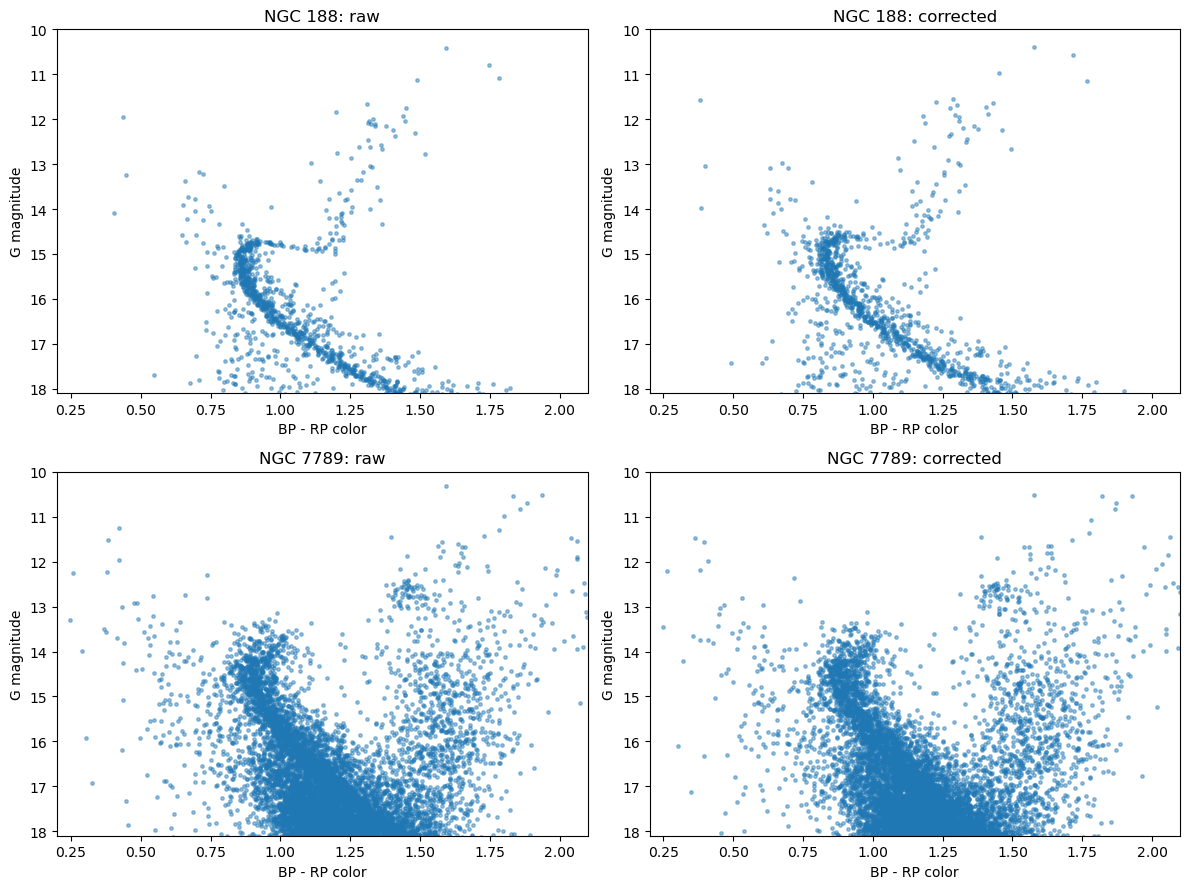

,cluster,same stars,raw color width,corrected color width,width change (%)
0,188,431,0.0242,0.0250,3.0921
1,7789,3775,0.0581,0.0637,9.5641


In [7]:
from scipy.stats import gaussian_kde
def residual(g,c,lo):
    gx,cx=[],[]
    for mid in np.arange(lo,17.9,.25):
        vals=np.asarray(c[(g>=mid-.125)&(g<mid+.125)])
        vals=vals[np.isfinite(vals)&(vals>.2)&(vals<2.8)]
        if len(vals)<8 or np.std(vals)==0: continue
        grid=np.linspace(np.quantile(vals,.05),np.quantile(vals,.95),180)
        density=gaussian_kde(vals,bw_method=max(.1,.035/np.std(vals)))(grid)
        gx.append(mid); cx.append(grid[np.argmax(density)])
    if len(gx)<2: return pd.Series(np.nan,index=c.index)
    return c-np.interp(g,gx,cx,left=np.nan,right=np.nan)
fig,axes=plt.subplots(2,2,figsize=(12,9)); widths=[]
for row,(n,d) in enumerate(samples.items()):
    for ax,gcol,ccol,label in zip(axes[row],['phot_g_mean_mag','phot_g_mean_mag_corrected'],['bp_rp','bp_rp_corrected'],['raw','corrected']):
        ax.scatter(d[ccol],d[gcol],s=6,color='tab:blue',alpha=.45)
        ax.set(title=f'NGC {n}: {label}',xlabel='BP - RP color',ylabel='G magnitude',xlim=(.2,2.1),ylim=(18.1,10))
    lo=15.8 if n==188 else 15.3
    r=residual(d.phot_g_mean_mag,d.bp_rp,lo)
    c=residual(d.phot_g_mean_mag_corrected,d.bp_rp_corrected,lo)
    same=(d.phot_g_mean_mag>=lo)&(d.phot_g_mean_mag<17.7)&(r.abs()<.2)&r.notna()&c.notna()
    mad=lambda x: np.median(np.abs(x-np.median(x)))
    rw,cw=mad(r[same]),mad(c[same])
    widths.append({'cluster':n,'same stars':same.sum(),'raw color width':rw,'corrected color width':cw,'width change (%)':100*(cw/rw-1)})
plt.tight_layout(); plt.show()
display(pd.DataFrame(widths).round(4))

What the saved results show

NGC 188 has 1,639 final core stars. Its PM model also produces a core sample, while the parallax model never reaches 80%. The candidate tables show which blue and red outliers survive the final selection and which are variable.

NGC 7789 has 253 final core stars. Its PM model peaks near 75%, and its parallax model peaks near 32%, so neither has an 80% core and parallax has no 50% sample. The combined model still assigns core membership to some stars. This disagreement is visible in the model diagrams and overlap tables.

The blue and red objects listed here are taken from the pipeline's final 50%+ sample. Their saved membership scores remain visible so you can distinguish strong assignments from borderline ones. Color boxes identify places to inspect, rather than confirming stellar types.

Core stars: saved probability of 80% or higher

Repeat the plots above with core stars only. Model panels use each model's own saved probability. The candidate and raw/corrected plots use saved final probability of at least 80%.

Select the saved core stars

Use the existing final membership probabilities in the CSVs and count the selected stars. This keeps the earlier 50% section unchanged.

In [8]:
core_samples={n:d.loc[d.final_member_prob>=.8].copy() for n,d in data.items()}
display(pd.DataFrame([{'cluster':n,'final core stars':len(d)} for n,d in core_samples.items()]))

,cluster,final core stars
0,188,1639
1,7789,253


Compare the models using core stars

Each panel shows only stars with at least 80% probability in that model. Empty panels mean that model has no core stars.

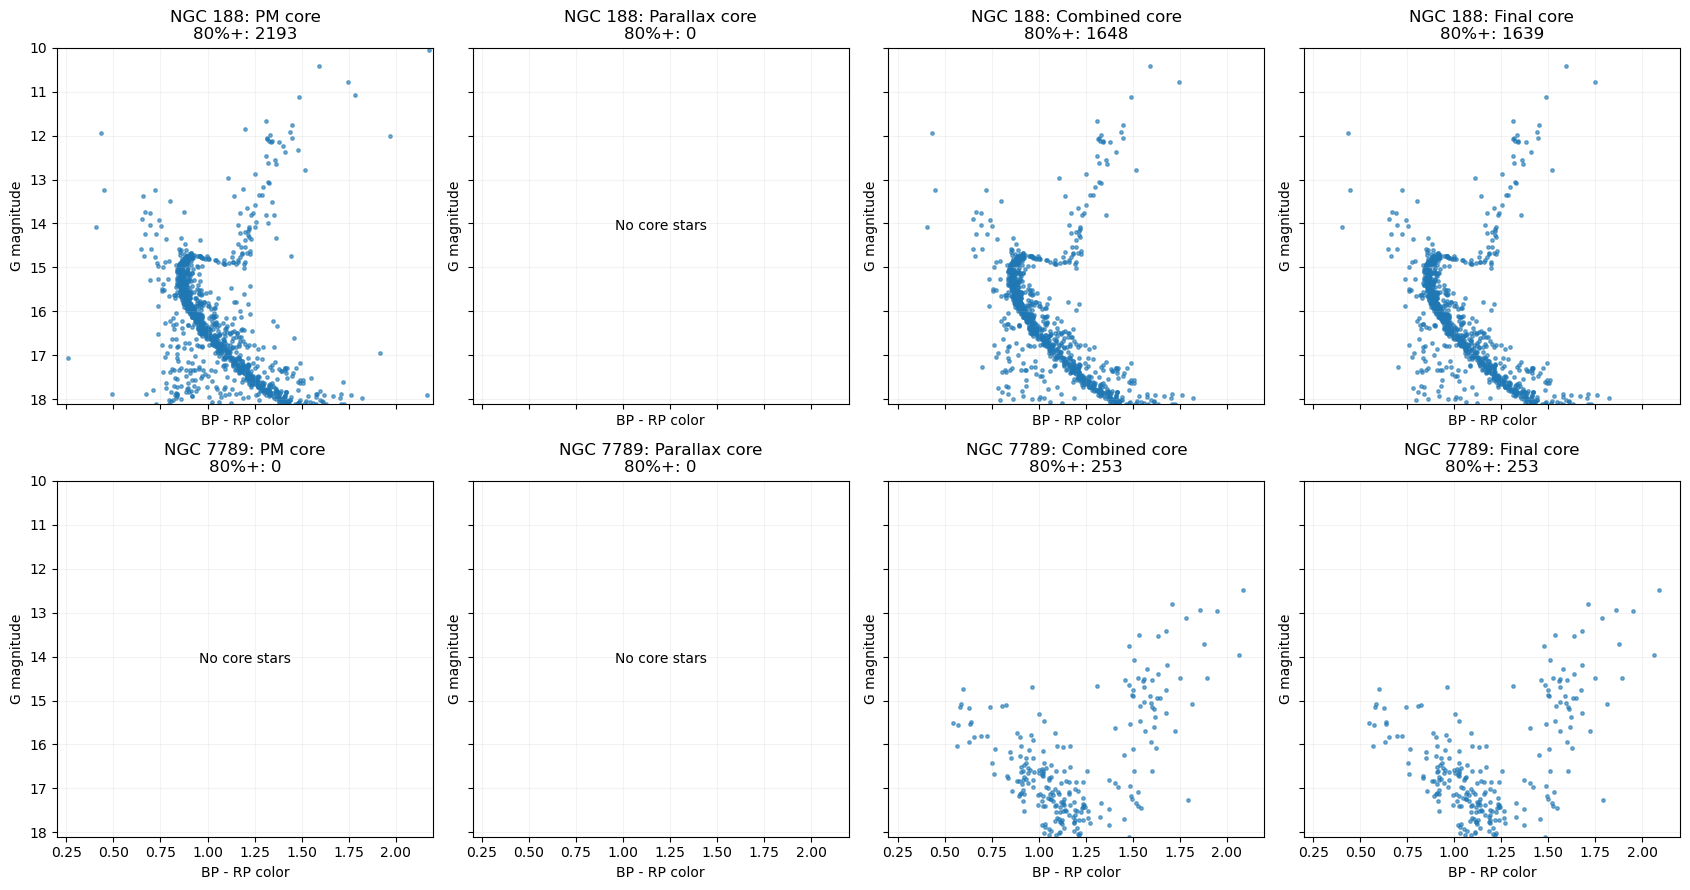

In [9]:
fig,axes=plt.subplots(2,4,figsize=(17,9),sharex=True,sharey=True)
for row,(n,d) in enumerate(data.items()):
    for ax,(label,col) in zip(axes[row],models.items()):
        stars=d.loc[d[col]>=.8]
        ax.scatter(stars.bp_rp,stars.phot_g_mean_mag,s=6,color='tab:blue',alpha=.6,rasterized=True)
        ax.set(title=f'NGC {n}: {label} core\n80%+: {len(stars)}',xlabel='BP - RP color',ylabel='G magnitude',xlim=(.2,2.2),ylim=(18.1,10))
        if stars.empty: ax.text(.5,.5,'No core stars',ha='center',va='center',transform=ax.transAxes)
        ax.grid(alpha=.15)
plt.tight_layout(); plt.show()

Compare saved probabilities for final core stars

The plots show only final core stars, with 80% reference lines. The overlap tables count stars meeting 80% in both named models across the full CSV.

NGC 188: stars at or above 80% in both models (diagonal = model total)


,PM,Parallax,Combined,Final
PM,2193,0,1537,1535
Parallax,0,0,0,0
Combined,1537,0,1648,1639
Final,1535,0,1639,1639


NGC 7789: stars at or above 80% in both models (diagonal = model total)


,PM,Parallax,Combined,Final
PM,0,0,0,0
Parallax,0,0,0,0
Combined,0,0,253,253
Final,0,0,253,253


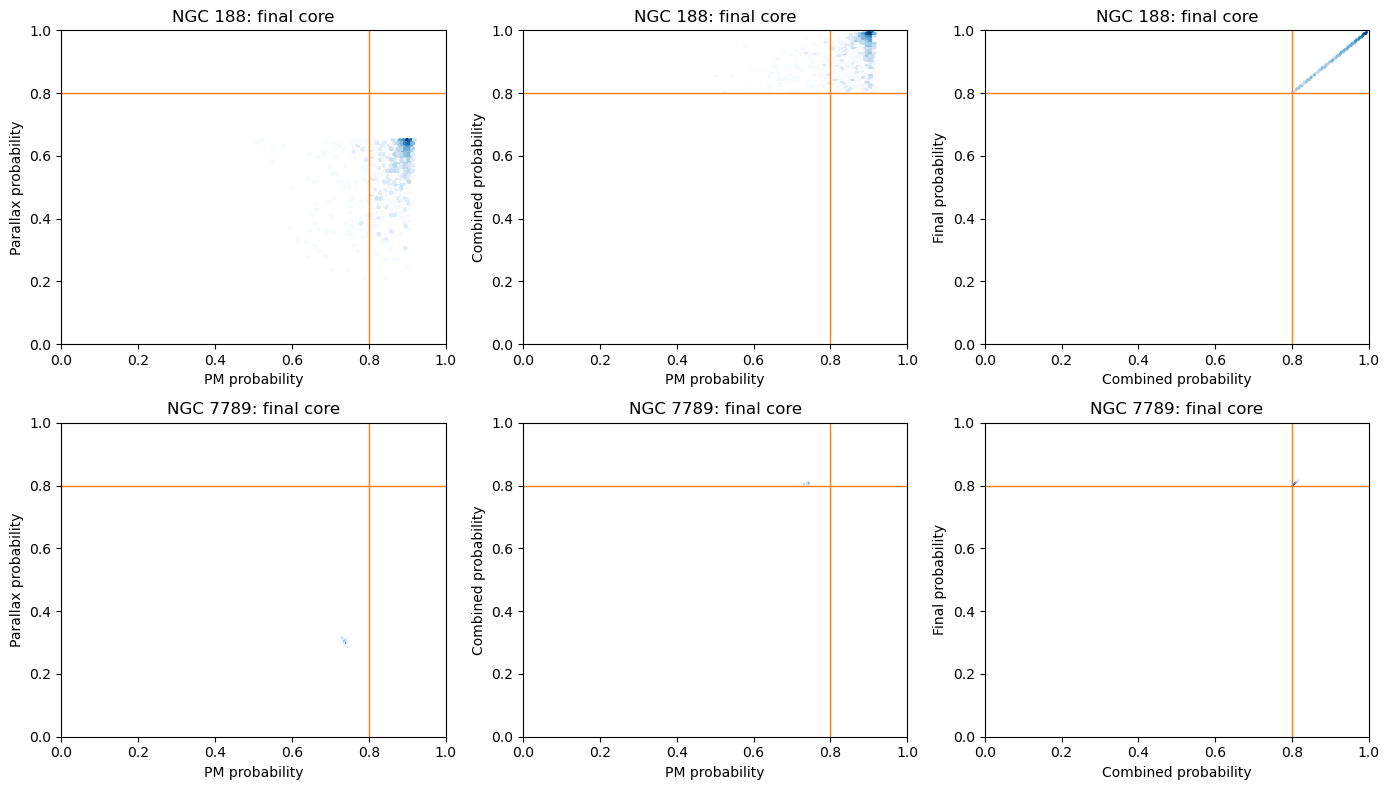

In [10]:
fig,axes=plt.subplots(2,3,figsize=(14,8))
pairs=[('PM','Parallax'),('PM','Combined'),('Combined','Final')]
for row,(n,d) in enumerate(core_samples.items()):
    for ax,(left,right) in zip(axes[row],pairs):
        ax.hexbin(d[models[left]],d[models[right]],gridsize=45,mincnt=1,bins='log',cmap='Blues')
        ax.axvline(.8,color='tab:orange',linewidth=1); ax.axhline(.8,color='tab:orange',linewidth=1)
        ax.set(title=f'NGC {n}: final core',xlabel=f'{left} probability',ylabel=f'{right} probability',xlim=(0,1),ylim=(0,1))
    masks={label:data[n][col]>=.8 for label,col in models.items()}
    overlap=pd.DataFrame({right:{left:int((masks[left]&masks[right]).sum()) for left in models} for right in models})
    print(f'NGC {n}: stars at or above 80% in both models (diagonal = model total)')
    display(overlap)
plt.tight_layout(); plt.show()

Inspect blue and red candidates among core stars

Use the same color and magnitude boxes as above, restricted to the saved final core sample. The plots and short tables show which interesting objects remain at 80%.

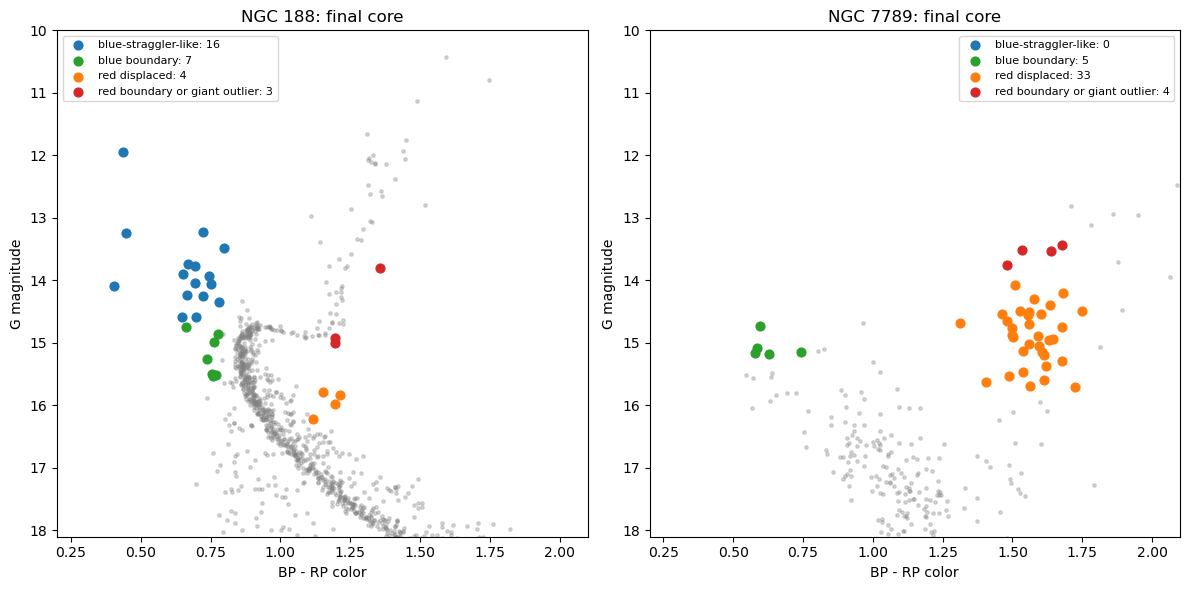

NGC 188: 30 objects in the inspection boxes


,stars,saved_core
region,,
blue boundary,7,7
blue-straggler-like,16,16
red boundary or giant outlier,3,3
red displaced,4,4


Showing up to 8 objects per region, highest saved probability first. All core_candidates remain in the core_candidates dictionary.


,source_id,region,phot_g_mean_mag,bp_rp,radial_velocity,phot_variable_flag,final_member_prob,saved core
0,573943149851092736,blue boundary,14.865,0.775,NaN,NOT_AVAILABLE,0.991,True
1,573939679517550848,blue boundary,15.261,0.736,NaN,NOT_AVAILABLE,0.991,True
2,573941809821331456,blue boundary,15.512,0.771,NaN,NOT_AVAILABLE,0.990,True
3,573944077564006528,blue boundary,14.741,0.662,NaN,NOT_AVAILABLE,0.988,True
4,573944283722429952,blue boundary,14.986,0.762,NaN,VARIABLE,0.987,True
5,573947444818423680,blue boundary,15.492,0.757,NaN,NOT_AVAILABLE,0.929,True
6,573965689839593472,blue boundary,15.531,0.759,NaN,NOT_AVAILABLE,0.840,True
7,573941397504457344,blue-straggler-like,13.902,0.653,-44.797,NOT_AVAILABLE,0.993,True
8,573941294425258496,blue-straggler-like,14.344,0.781,-41.278,NOT_AVAILABLE,0.993,True
9,573938408207239296,blue-straggler-like,14.090,0.405,NaN,NOT_AVAILABLE,0.993,True


NGC 7789: 42 objects in the inspection boxes


,stars,saved_core
region,,
blue boundary,5,5
red boundary or giant outlier,4,4
red displaced,33,33


Showing up to 8 objects per region, highest saved probability first. All core_candidates remain in the core_candidates dictionary.


,source_id,region,phot_g_mean_mag,bp_rp,radial_velocity,phot_variable_flag,final_member_prob,saved core
0,1995079658387248000,blue boundary,15.086,0.586,NaN,NOT_AVAILABLE,0.817,True
1,1995080826618300032,blue boundary,15.148,0.743,NaN,NOT_AVAILABLE,0.809,True
2,1998085894972110592,blue boundary,15.154,0.579,NaN,NOT_AVAILABLE,0.809,True
3,1995083815915526656,blue boundary,15.172,0.628,NaN,NOT_AVAILABLE,0.808,True
4,1995076394212435072,blue boundary,14.730,0.597,NaN,NOT_AVAILABLE,0.803,True
5,1994988261480487296,red boundary or giant outlier,13.520,1.534,-41.474,NOT_AVAILABLE,0.817,True
6,1995077699882187264,red boundary or giant outlier,13.427,1.678,-65.890,NOT_AVAILABLE,0.816,True
7,1994994205715907840,red boundary or giant outlier,13.761,1.479,-22.747,NOT_AVAILABLE,0.809,True
8,1995063955986667648,red boundary or giant outlier,13.523,1.637,-46.590,NOT_AVAILABLE,0.805,True
9,421041730004653056,red displaced,15.201,1.612,NaN,NOT_AVAILABLE,0.816,True


In [11]:
core_candidates={}
colors={'blue-straggler-like':'tab:blue','blue boundary':'tab:green','red displaced':'tab:orange','red boundary or giant outlier':'tab:red'}
fig,axes=plt.subplots(1,2,figsize=(12,6))
for ax,(n,d) in zip(axes,core_samples.items()):
    g,c=d.phot_g_mean_mag,d.bp_rp
    if n==188:
        boxes={'blue-straggler-like':(g<14.7)&c.between(.2,.83,inclusive='neither'),'blue boundary':g.between(14.7,15.6,inclusive='left')&c.between(.2,.78,inclusive='neither'),'red displaced':g.between(15.05,16.3,inclusive='neither')&c.between(1.1,1.8,inclusive='neither'),'red boundary or giant outlier':((g>14.9)&(g<=15.05)&c.between(1.1,1.8,inclusive='neither'))|(g.between(13.6,14.85,inclusive='neither')&c.between(1.32,2,inclusive='neither'))}
    else:
        boxes={'blue-straggler-like':(g<14.2)&c.between(.2,.78,inclusive='neither'),'blue boundary':g.between(14.2,15.3,inclusive='left')&c.between(.2,.78,inclusive='neither'),'red displaced':g.between(13.8,15.8,inclusive='neither')&c.between(1.15,1.8,inclusive='neither'),'red boundary or giant outlier':(g>13.2)&(g<=13.8)&c.between(1.18,1.8,inclusive='neither')}
    ax.scatter(c,g,s=6,color='gray',alpha=.3)
    parts=[]
    for label,mask in boxes.items():
        part=d.loc[mask].copy(); part['region']=label; parts.append(part)
        ax.scatter(part.bp_rp,part.phot_g_mean_mag,s=40,color=colors[label],label=f'{label}: {len(part)}')
    core_candidates[n]=pd.concat(parts).drop_duplicates('source_id')
    core_candidates[n]['saved core']=core_candidates[n].final_member_prob>=.8
    ax.set(title=f'NGC {n}: final core',xlabel='BP - RP color',ylabel='G magnitude',xlim=(.2,2.1),ylim=(18.1,10)); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
columns=['source_id','region','phot_g_mean_mag','bp_rp','radial_velocity','phot_variable_flag','final_member_prob','saved core']
for n,d in core_candidates.items():
    print(f'NGC {n}: {len(d)} objects in the inspection boxes')
    display(d.groupby('region').agg(stars=('source_id','size'),saved_core=('saved core','sum')))
    shortlist=d.sort_values('final_member_prob',ascending=False).groupby('region',sort=False).head(8)
    print('Showing up to 8 objects per region, highest saved probability first. All core_candidates remain in the core_candidates dictionary.')
    display(shortlist[columns].sort_values(['region','final_member_prob'],ascending=[True,False]).round(3).reset_index(drop=True))

Compare raw and corrected core diagrams

Plot the same final core stars before and after correction. The width calculation uses the same method and magnitude ranges as above. Missing widths mean too few suitable stars to measure the sequence.

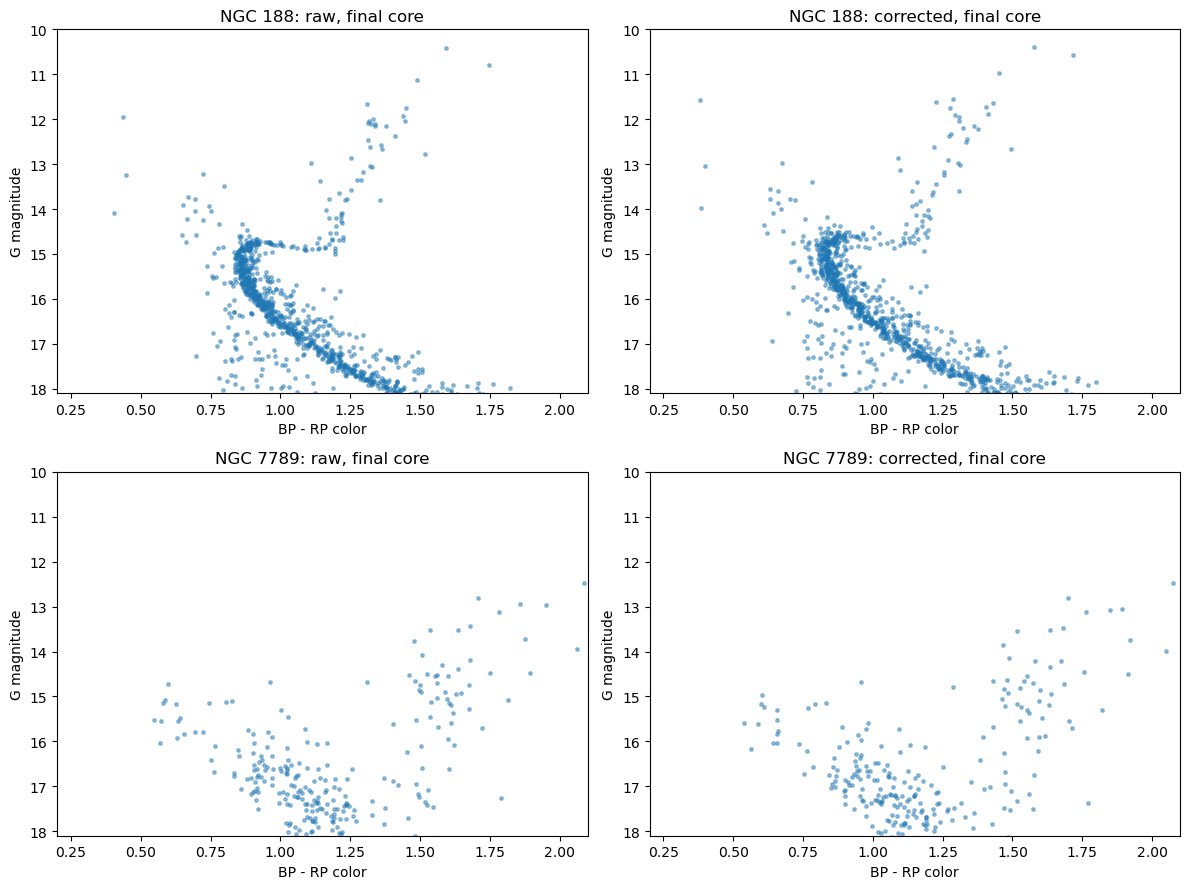

,cluster,same stars,raw color width,corrected color width,width change (%)
0,188,381,0.0210,0.0221,5.1665
1,7789,114,0.0537,0.0724,34.6893


In [12]:
fig,axes=plt.subplots(2,2,figsize=(12,9)); core_widths=[]
for row,(n,d) in enumerate(core_samples.items()):
    for ax,gcol,ccol,label in zip(axes[row],['phot_g_mean_mag','phot_g_mean_mag_corrected'],['bp_rp','bp_rp_corrected'],['raw','corrected']):
        ax.scatter(d[ccol],d[gcol],s=6,color='tab:blue',alpha=.45)
        ax.set(title=f'NGC {n}: {label}, final core',xlabel='BP - RP color',ylabel='G magnitude',xlim=(.2,2.1),ylim=(18.1,10))
    lo=15.8 if n==188 else 15.3
    r=residual(d.phot_g_mean_mag,d.bp_rp,lo)
    c=residual(d.phot_g_mean_mag_corrected,d.bp_rp_corrected,lo)
    same=(d.phot_g_mean_mag>=lo)&(d.phot_g_mean_mag<17.7)&(r.abs()<.2)&r.notna()&c.notna()
    mad=lambda x: np.median(np.abs(x-np.median(x)))
    rw,cw=(mad(r[same]),mad(c[same])) if same.any() else (np.nan,np.nan)
    core_widths.append({'cluster':n,'same stars':same.sum(),'raw color width':rw,'corrected color width':cw,'width change (%)':100*(cw/rw-1) if np.isfinite(rw) and rw>0 else np.nan})
plt.tight_layout(); plt.show()
display(pd.DataFrame(core_widths).round(4))